# M1 — Crop & Fertilizer Recommender (final)

Smart Crop Advisory System (SIH25010), module M1.

**Pipeline**
- **Stage 1** — soil/climate → ranked crops with calibrated probabilities.
- **Stage 2** — soil/climate + predicted crop → fertilizer, with a stated source tier.

**Ground rules**
- Every number shown here is logged in `RESULTS.md` with the command that produced it.
- Every metric is reported with a baseline and its fold-to-fold spread (std, ddof = 1).
- Known limitations are stated, not hidden.

**What this notebook does**
- Loads the logged results and the saved models.
- Recomputes the key checks live: test metrics from the saved models, tier coverage, the
  dataset range mismatch, and smoke tests.
- Retraining everything takes about 15 minutes, so it is not repeated here. The commands are in
  the last section.

In [1]:
import os, warnings
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")           # silence TensorFlow C++ start-up logging
warnings.filterwarnings("ignore", message="IProgress not found")
import json, sys, platform
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(ROOT / "scripts"))
import keras, sklearn, shap
R = lambda p: json.loads((ROOT / "results" / p).read_text())
pd.set_option("display.precision", 4); pd.set_option("display.max_colwidth", None)
print(f"Python {platform.python_version()} | keras {keras.__version__} (backend {keras.backend.backend()}) | "
      f"scikit-learn {sklearn.__version__} | shap {shap.__version__}")

Python 3.12.3 | keras 3.15.1 (backend tensorflow) | scikit-learn 1.9.1 | shap 0.54.1


## 1. Data

In [2]:
from task1_calibration import load_xy, NUM_COLS_CROP, SEED
from train_stage2_notebook import load_fert_df
crop_df, X, y, enc = load_xy()
fert_df = load_fert_df()
print(f"Crop data: {crop_df.shape[0]} rows, {len(enc.classes_)} crops, "
      f"{crop_df['label'].value_counts().min()}-{crop_df['label'].value_counts().max()} rows per crop")
print(f"Fertilizer data: {fert_df.shape[0]} rows, {fert_df['label'].nunique()} crop labels, "
      f"{fert_df['soil_type'].nunique()} soil types, {fert_df['fertilizer'].nunique()} fertilizer classes")
display(fert_df["fertilizer"].value_counts().rename("rows").to_frame().T)
shared = sorted(set(crop_df["label"]) & set(fert_df["label"]))
print("Crop names shared by both datasets (after paddy -> rice):", shared)

Crop data: 2200 rows, 22 crops, 100-100 rows per crop
Fertilizer data: 99 rows, 11 crop labels, 5 soil types, 7 fertilizer classes


fertilizer,Urea,DAP,28-28,14-35-14,20-20,17-17-17,10-26-26
rows,22,18,17,14,14,7,7


Crop names shared by both datasets (after paddy -> rice): ['cotton', 'maize', 'rice']


## 2. Stage 1 — crop model

Architecture: 7 standardised inputs → Dense 64 ReLU → Dropout 0.2 → Dense 32 ReLU → Softmax 22
(3,318 parameters).

Deployed model: a **5-seed ensemble with temperature scaling**, chosen in Task 1.
`docs/architecture.md` marks each hyperparameter as default, reasoned or validated.

In [3]:
from task1_calibration import build_crop_model
m = build_crop_model(7, 22); print("parameters:", m.count_params())

parameters: 3318


### 2.1 Task 1: calibration

Setup:
- 5-fold stratified CV with the scaler fit inside each fold, 40 epochs.
- 15% of each training fold is held out to fit the temperature T. The test folds are never used
  for fitting or selection.

Finding: the baseline was slightly **under**-confident on real inputs, so T < 1 in every fold.
The real problem was out-of-range inputs.

In [4]:
b, v = R("task1/baseline.json"), R("task1/variants.json")
lk = b["leakage_check"]
rows = [("leaky-25ep (scaler on all rows)", lk["leaky_scaler_on_all_rows"]["summary"]),
        ("in-fold-25ep", lk["scaler_inside_fold"]["summary"])]
display(pd.DataFrame({n: {f"{k} mean": s[k]["mean"] for k in ("accuracy", "macro_f1")} |
                         {f"{k} std": s[k]["std"] for k in ("accuracy", "macro_f1")} for n, s in rows}).T)
tab = {"class-prior reference": b["prior_reference_summary"]} | {n: r["summary"] for n, r in v["variants"].items()}
cols = ["accuracy", "macro_f1", "ece", "nll", "brier", "mean_confidence"]
display(pd.DataFrame({n: {c: f'{s[c]["mean"]:.4f} ± {s[c]["std"]:.4f}' for c in cols} for n, s in tab.items()}).T)
print("Temperatures per fold (E_ensemble5+TS):", np.round(v["variants"]["E_ensemble5+TS"]["temperatures"], 3))

,accuracy mean,macro_f1 mean,accuracy std,macro_f1 std
leaky-25ep (scaler on all rows),0.9732,0.9728,0.0076,0.0079
in-fold-25ep,0.9727,0.9724,0.0079,0.0082


,accuracy,macro_f1,ece,nll,brier,mean_confidence
class-prior reference,0.0455 ± 0.0000,0.0040 ± 0.0000,0.0000 ± 0.0000,3.0910 ± 0.0000,0.9545 ± 0.0000,0.0455 ± 0.0000
A_baseline,0.9786 ± 0.0044,0.9785 ± 0.0045,0.0193 ± 0.0021,0.0663 ± 0.0085,0.0360 ± 0.0050,0.9647 ± 0.0033
B_ls0.05,0.9777 ± 0.0041,0.9777 ± 0.0042,0.0771 ± 0.0044,0.1319 ± 0.0090,0.0477 ± 0.0037,0.9019 ± 0.0047
B_ls0.1,0.9795 ± 0.0036,0.9795 ± 0.0037,0.1283 ± 0.0040,0.1907 ± 0.0079,0.0612 ± 0.0036,0.8521 ± 0.0045
C_A+TS,0.9786 ± 0.0044,0.9785 ± 0.0045,0.0125 ± 0.0020,0.0610 ± 0.0114,0.0349 ± 0.0059,0.9759 ± 0.0024
D_ls0.05+TS,0.9777 ± 0.0041,0.9777 ± 0.0042,0.0122 ± 0.0046,0.0621 ± 0.0106,0.0340 ± 0.0042,0.9765 ± 0.0019
E_ensemble5,0.9823 ± 0.0030,0.9823 ± 0.0030,0.0234 ± 0.0053,0.0630 ± 0.0049,0.0325 ± 0.0034,0.9634 ± 0.0026
E_ensemble5+TS,0.9823 ± 0.0030,0.9823 ± 0.0030,0.0134 ± 0.0023,0.0550 ± 0.0095,0.0304 ± 0.0052,0.9775 ± 0.0054


Temperatures per fold (E_ensemble5+TS): [0.606 0.85  0.683 0.613 0.778]


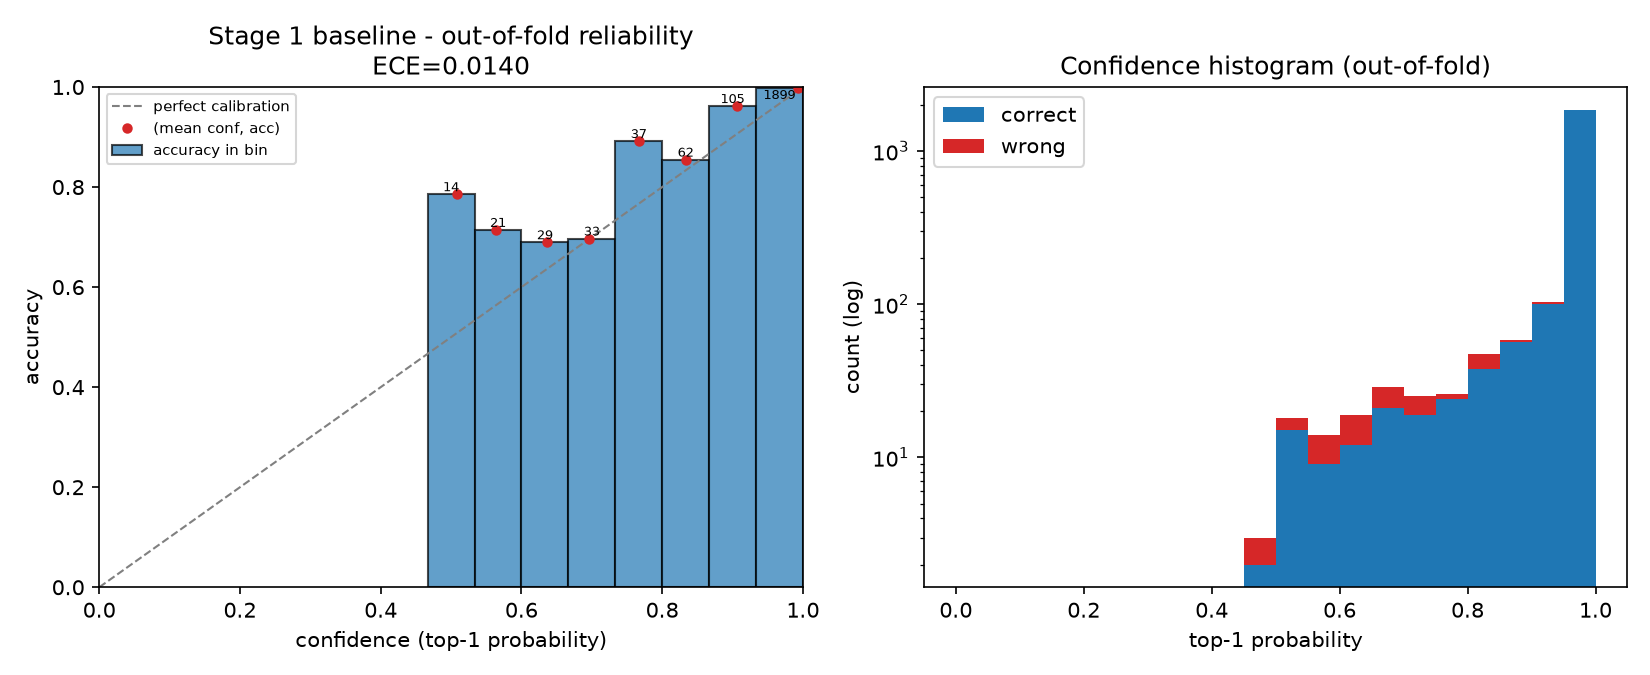

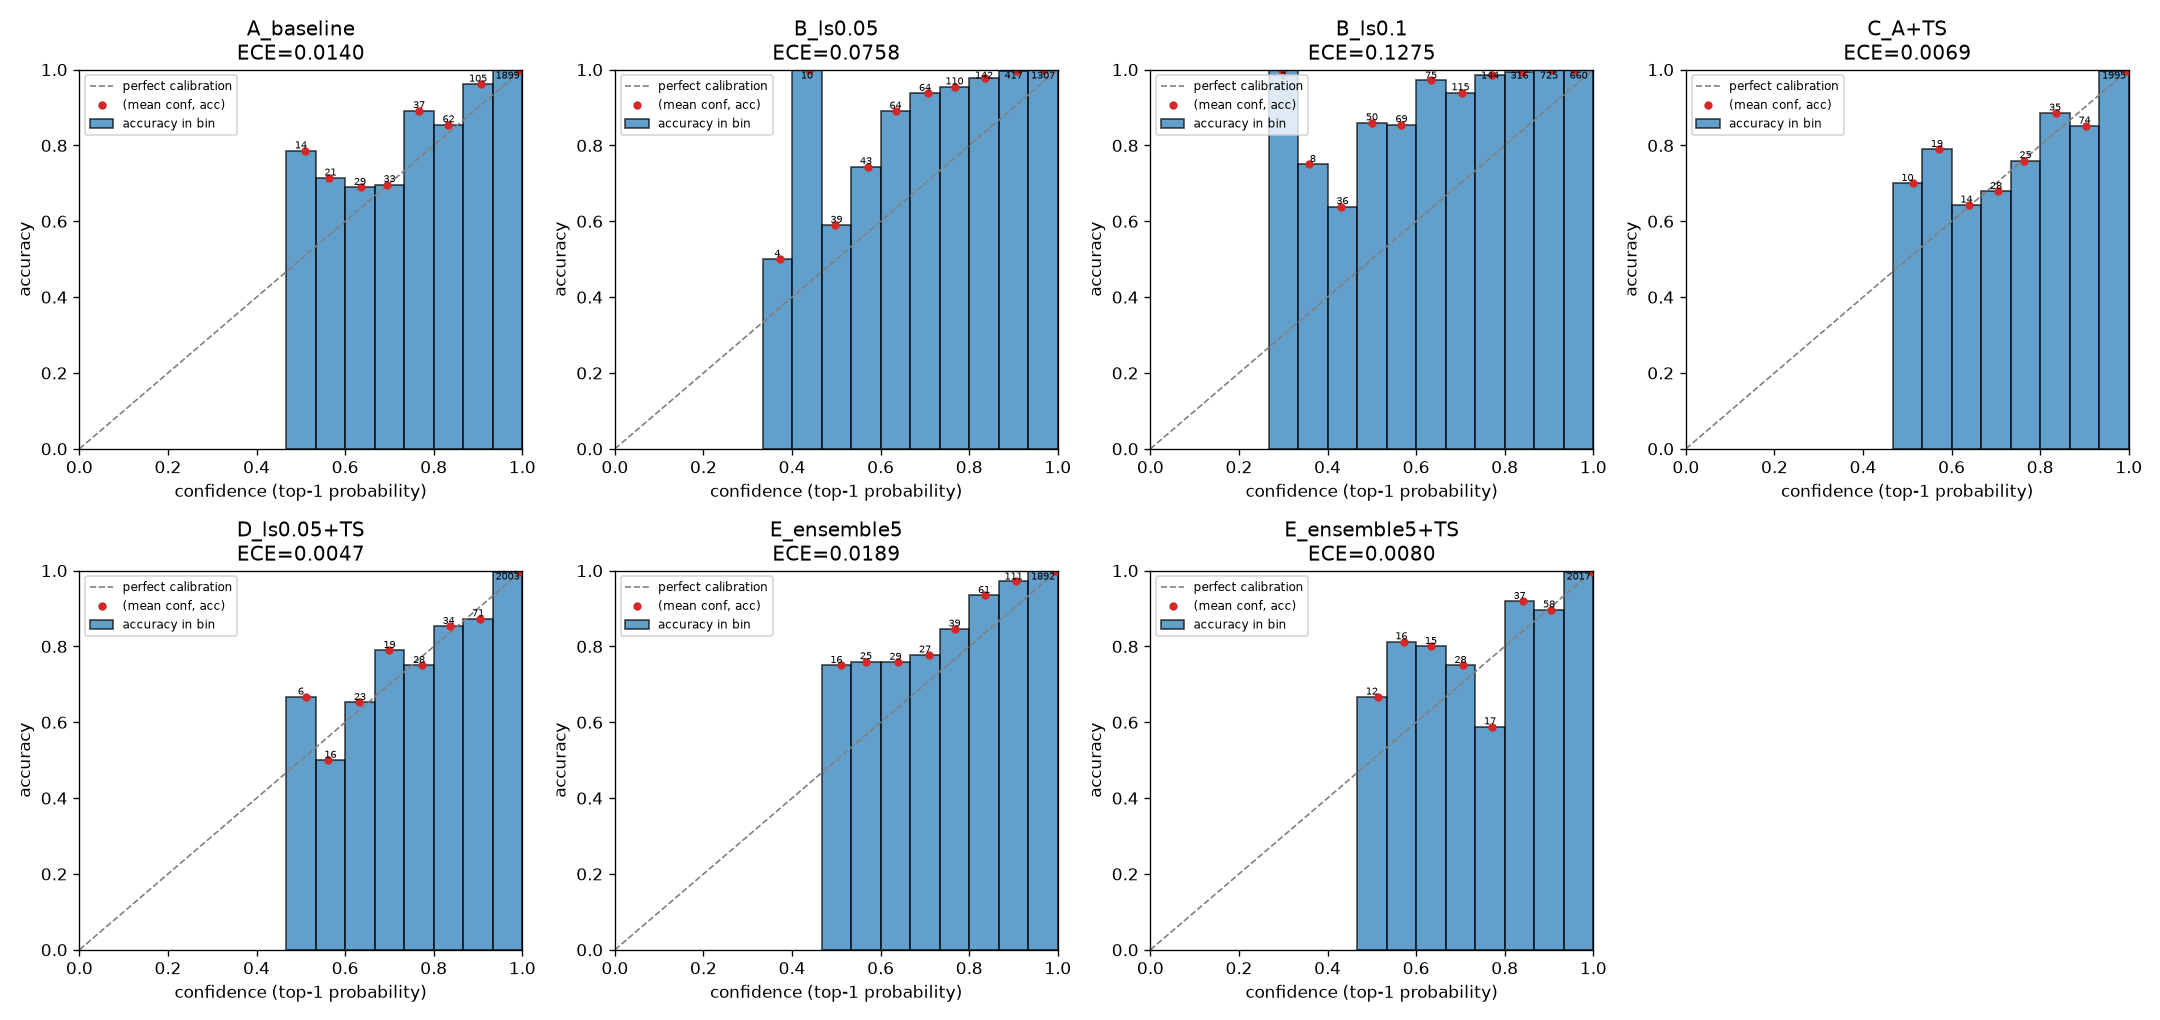

In [5]:
display(Image(filename=str(ROOT / "results/task1/baseline_reliability.png"), width=900))
display(Image(filename=str(ROOT / "results/task1/variants_reliability.png"), width=1000))

### 2.2 Out-of-range inputs

None of the calibration methods fixes out-of-range inputs; some barely change. That is why an
**input-range guard** was added: any feature outside the training min/max ± 10% of its range
sets the status to `out_of_range`.

In [6]:
pr = pd.DataFrame({n: r["probe_top1_median"] for n, r in v["variants"].items()})
display(pr.round(3))

,A_baseline,B_ls0.05,B_ls0.1,C_A+TS,D_ls0.05+TS,E_ensemble5,E_ensemble5+TS
rice_like (in-distribution),0.728,0.585,0.524,0.802,0.708,0.784,0.840
all zeros,0.999,0.967,0.964,1.000,0.999,0.813,0.917
all features 2x train max,1.000,1.000,1.000,1.000,1.000,1.000,1.000
all features 5x train max,1.000,1.000,1.000,1.000,1.000,1.000,1.000
"N = 3x train max, rest median",1.000,1.000,0.999,1.000,1.000,1.000,1.000
"P = 3x train max, rest median",1.000,0.799,0.687,1.000,0.983,0.620,0.739
"K = 3x train max, rest median",1.000,0.962,0.931,1.000,0.998,0.782,0.919
"temperature = 3x train max, rest median",1.000,0.950,0.886,1.000,0.999,1.000,1.000
"humidity = 3x train max, rest median",1.000,1.000,1.000,1.000,1.000,1.000,1.000
"ph = 3x train max, rest median",1.000,0.996,0.895,1.000,1.000,0.999,1.000


### 2.3 Deployed model on the held-out test split (recomputed live from `models/`)

- **Split:** the same 80/20 split as the original notebook (440 test rows).
- **Uncertain flag:** t = 0.75, chosen as the smallest threshold whose accepted predictions
  reach ≥ 99% accuracy on out-of-fold predictions.

In [7]:
from sklearn.model_selection import train_test_split
from m1.calibration import all_metrics
from m1.recommender import get_recommender
rec = get_recommender()
_, te = train_test_split(np.arange(len(y)), test_size=0.2, stratify=y, random_state=SEED)
p = rec.crop_probs(X[te])
live = all_metrics(p, y[te]); fin = R("task1/final.json")
conf = p.max(1); t = rec.uncertain_threshold
display(pd.DataFrame({"deployed (live)": live, "logged final.json": fin["test_metrics"],
                      "single model A, same split (logged)": fin["test_metrics_A_same_split"]}).T)
print(f"threshold t={t}: coverage {np.mean(conf >= t):.4f}, accuracy on accepted "
      f"{np.mean((p.argmax(1) == y[te])[conf >= t]):.4f}, flagged {int(np.sum(conf < t))}/{len(te)}")
display(pd.DataFrame(fin["oof_coverage_curve"]).set_index("threshold").round(4))

,accuracy,macro_f1,ece,nll,brier,mean_confidence
deployed (live),0.9841,0.9840,0.0150,0.0378,0.0221,0.9785
logged final.json,0.9841,0.9840,0.0150,0.0378,0.0221,0.9785
"single model A, same split (logged)",0.9773,0.9771,0.0158,0.0580,0.0321,0.9645


threshold t=0.75: coverage 0.9659, accuracy on accepted 0.9953, flagged 15/440


,coverage,accuracy_accepted,accuracy_flagged,n_flagged
threshold,,,,
0.30,1.0000,0.9823,NaN,0
0.35,1.0000,0.9823,NaN,0
0.40,1.0000,0.9823,NaN,0
0.45,1.0000,0.9823,NaN,0
0.50,1.0000,0.9823,NaN,0
0.55,0.9927,0.9840,0.7500,16
0.60,0.9873,0.9853,0.7500,28
0.65,0.9827,0.9861,0.7632,38
0.70,0.9764,0.9874,0.7692,52


## 3. Stage 2 — fertilizer, with source tiers (Task 2)

Only 3 crop names overlap between the two datasets. Each answer therefore states its source:

| Tier | Source |
|---|---|
| Tier 1 | The ML model, for crops present in the fertilizer data. |
| Tier 2 | The ML model queried with the crop group `pulses`, for the seven pulse crops. This is an assumption, documented in `docs/fertilizer_tiers.md`. |
| None | "No verified fertilizer data". |

In [8]:
from m1 import tiers
cov = tiers.coverage(enc.classes_)
display(pd.DataFrame({k: {"crops": ", ".join(c), "count": len(c), "share of 22": f"{len(c)/22:.1%}"}
                      for k, c in cov.items()}).T)

,crops,count,share of 22
tier1,"cotton, maize, rice",3,13.6%
tier2,"blackgram, chickpea, kidneybeans, lentil, mothbeans, mungbean, pigeonpeas",7,31.8%
none,"apple, banana, coconut, coffee, grapes, jute, mango, muskmelon, orange, papaya, pomegranate, watermelon",12,54.5%


### 3.1 Range mismatch between the datasets (recomputed live)

The fertilizer data covers a much narrower range of conditions than the crop data. Outside that
range the stage-2 model is extrapolating, and the app warns about it on every answer.

In [9]:
g = rec.fert_guard
cols5 = ["temperature", "humidity", "N", "K", "P"]
idx = [g.feature_names.index(c) for c in cols5]
served = crop_df[crop_df["label"].isin(cov["tier1"] + cov["tier2"])][cols5].values
inside = (served >= g.lower_[idx]) & (served <= g.upper_[idx])
display(pd.DataFrame({"fertilizer-data min": g.train_min_[idx], "fertilizer-data max": g.train_max_[idx],
                      "crop-data min (Tier 1/2)": served.min(0), "crop-data max (Tier 1/2)": served.max(0),
                      "share of crop rows inside": inside.mean(0)}, index=cols5).round(2))
print(f"Crop-data rows (Tier 1/2 crops) inside the stage-2 range on all 5 features: {inside.all(1).mean():.1%}")

,fertilizer-data min,fertilizer-data max,crop-data min (Tier 1/2),crop-data max (Tier 1/2),share of crop rows inside
temperature,25.0,38.0,15.33,36.98,0.59
humidity,50.0,72.0,14.26,90.00,0.42
N,4.0,42.0,0.00,140.00,0.62
K,0.0,19.0,15.00,85.00,0.46
P,0.0,42.0,35.00,80.00,0.24


Crop-data rows (Tier 1/2 crops) inside the stage-2 range on all 5 features: 1.7%


## 4. Benchmark (Tasks 3 + 4)

Protocol:
- Stage 1: the same stratified 5-fold.
- Stage 2: repeated stratified 5-fold × 3 (n = 99).
- Preprocessing is fit inside each fold, seeds are fixed, and there is no hyperparameter search.

In [10]:
bm = R("benchmark/benchmark.json")
def bench(stage):
    cols = ["accuracy", "macro_f1", "ece", "nll", "params", "train_s"]
    return pd.DataFrame({n: {c: (f'{r["summary"][c]["mean"]:,.0f}' if c == "params" else
                                 f'{r["summary"][c]["mean"]:.4f} ± {r["summary"][c]["std"]:.4f}') for c in cols}
                         for n, r in bm[stage].items()}).T
display(Markdown("**Stage 1**")); display(bench("stage1"))
display(Markdown("**Stage 2**")); display(bench("stage2"))
def paired(stage, a, b, k):
    d = np.array([f[k] for f in bm[stage][a]["per_fold"]]) - np.array([f[k] for f in bm[stage][b]["per_fold"]])
    return f"{d.mean():+.4f} ± {d.std(ddof=1):.4f} (ahead/tied/behind: {(d>0).sum()}/{(d==0).sum()}/{(d<0).sum()})"
print("Stage 1, RF − MLP accuracy:      ", paired("stage1", "RandomForest (300 trees)", "MLP 64-32 (current)", "accuracy"))
print("Stage 1, LightGBM − MLP accuracy:", paired("stage1", "LightGBM (defaults)", "MLP 64-32 (current)", "accuracy"))
print("Stage 2, RF − emb. NN accuracy:  ", paired("stage2", "RandomForest (one-hot, 300 trees)", "Embedding NN (current)", "accuracy"))
print("Stage 2, RF − emb. NN macro-F1:  ", paired("stage2", "RandomForest (one-hot, 300 trees)", "Embedding NN (current)", "macro_f1"))
print("Stage 2, emb. − one-hot NN NLL:  ", paired("stage2", "Embedding NN (current)", "One-hot NN", "nll"))

**Stage 1**

,accuracy,macro_f1,ece,nll,params,train_s
LogisticRegression,0.9709 ± 0.0025,0.9707 ± 0.0025,0.1288 ± 0.0025,0.2102 ± 0.0141,176,0.1196 ± 0.0212
RandomForest (300 trees),0.9950 ± 0.0030,0.9950 ± 0.0030,0.0413 ± 0.0029,0.0518 ± 0.0018,"45,484",0.9604 ± 0.0184
LightGBM (defaults),0.9914 ± 0.0019,0.9913 ± 0.0019,0.0083 ± 0.0027,0.0312 ± 0.0096,"70,672",0.7069 ± 0.1019
MLP 64-32 (current),0.9805 ± 0.0038,0.9804 ± 0.0039,0.0166 ± 0.0047,0.0581 ± 0.0092,"3,318",11.4215 ± 0.2147


**Stage 2**

,accuracy,macro_f1,ece,nll,params,train_s
Majority class,0.2221 ± 0.0239,0.0518 ± 0.0045,0.7779 ± 0.0239,21.4940 ± 0.6606,0,0.0011 ± 0.0002
"RandomForest (one-hot, 300 trees)",0.9667 ± 0.0408,0.9266 ± 0.0908,0.3415 ± 0.0293,0.4932 ± 0.0382,"12,860",0.5692 ± 0.0736
Embedding NN (current),0.9330 ± 0.0407,0.8451 ± 0.0835,0.1839 ± 0.0360,0.2803 ± 0.0269,"3,272",4.6837 ± 0.7738
One-hot NN,0.8821 ± 0.0700,0.8007 ± 0.1317,0.1924 ± 0.0476,0.4187 ± 0.0699,"3,783",4.2282 ± 0.4470


Stage 1, RF − MLP accuracy:       +0.0145 ± 0.0026 (ahead/tied/behind: 5/0/0)
Stage 1, LightGBM − MLP accuracy: +0.0109 ± 0.0054 (ahead/tied/behind: 5/0/0)
Stage 2, RF − emb. NN accuracy:   +0.0337 ± 0.0589 (ahead/tied/behind: 8/6/1)
Stage 2, RF − emb. NN macro-F1:   +0.0815 ± 0.1353 (ahead/tied/behind: 10/1/4)
Stage 2, emb. − one-hot NN NLL:   -0.1384 ± 0.0600 (ahead/tied/behind: 0/0/15)


**Conclusions**

Stage 1: **tree models beat the MLP in all 5 folds.**
- RandomForest and LightGBM are ahead by 1.1–1.5 points of accuracy, several times the fold std.
- LightGBM is also better calibrated than the deployed ensemble + TS.

Stage 2: **RandomForest vs the embedding NN is within noise.**
- The paired differences are smaller than their split-to-split std.
- The test folds are ~20 rows, and the 15 splits are not independent.
- RF was ahead or tied in 14 of 15 splits on accuracy, so the direction favours RF but the size
  of the gap can't be measured with 99 rows.
- The NN has the better NLL in all 15 splits.
- Embeddings beat one-hot inputs on NLL in all 15 splits.

**Decision: neural networks for both stages,** because the project scope is deep learning.
- Stage 1 keeps the MLP ensemble + TS. Stage 2 uses the embedding NN, retrained leak-free on all
  99 rows.
- The cost is about 1.3 points of stage-1 accuracy, plus approximate (Kernel) rather than exact
  (Tree) SHAP.
- The tree models are kept as benchmark results.

## 5. Explainability (SHAP on the deployed models)

,crop model,fertilizer model
humidity,0.0395,0.0043
rainfall,0.0356,NaN
N,0.0317,0.1110
P,0.0287,0.1164
K,0.0236,0.0895
temperature,0.0123,0.0119
ph,0.0059,NaN
crop,NaN,0.0090
Moisture,NaN,0.0061
soil_type,NaN,0.0025


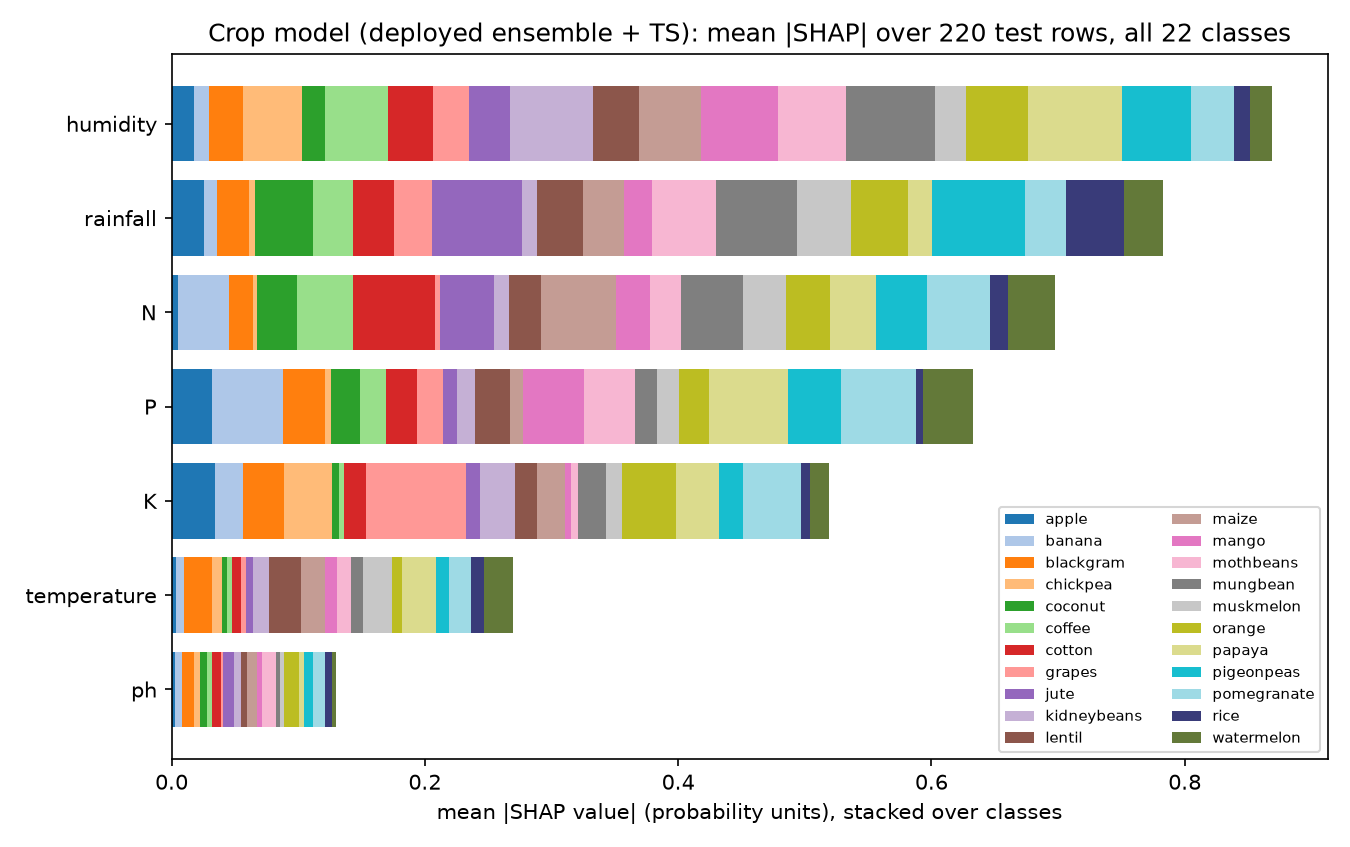

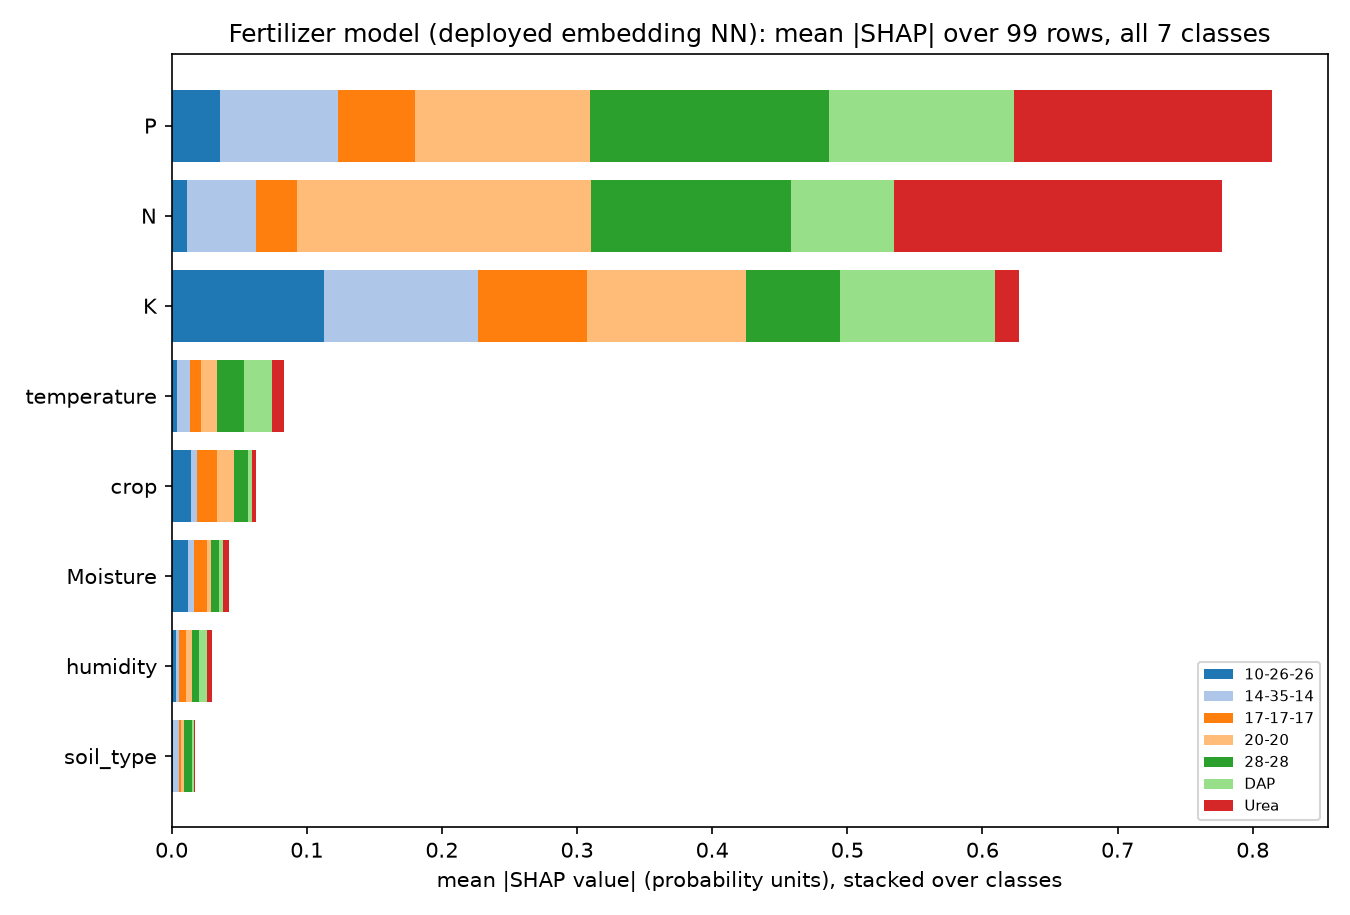

In [11]:
s = R("shap/shap_summary.json")
display(pd.DataFrame({"crop model": s["crop"]["mean_abs_shap_by_feature"],
                      "fertilizer model": s["fertilizer"]["mean_abs_shap_by_feature"]}).round(4))
display(Image(filename=str(ROOT / "results/shap/crop_shap_mean_abs.png"), width=850))
display(Image(filename=str(ROOT / "results/shap/fert_shap_mean_abs.png"), width=850))

**Reading the plots**
- **Crop:** humidity, rainfall and N/P/K drive the crop choice; pH matters least.
- **Fertilizer:** the choice is driven by N/P/K levels. Crop and soil type contribute little,
  which fits fertilizer names that are NPK grades.
- **Per prediction:** the app shows the top-3 SHAP drivers for every answer.

## 6. End-to-end examples (`recommend()`, the function the Gradio app calls)

Inputs: the rice-like smoke test, class means from the data, and out-of-range cases.

In [12]:
from m1.recommender import recommend
cm = lambda c: dict(zip(["N","P","K","temperature","humidity","ph","rainfall"],
                        crop_df.loc[crop_df["label"] == c, NUM_COLS_CROP].mean().round(1)))
cases = {"rice-like (N90 P42 K43 20.8C 82% pH6.5 202mm), Clayey": dict(N=90, P=42, K=43, temperature=20.8, humidity=82, ph=6.5, rainfall=202, soil_type="Clayey", moisture=45),
         "chickpea class mean, Loamy": cm("chickpea") | dict(soil_type="Loamy", moisture=40),
         "mango class mean, Loamy": cm("mango") | dict(soil_type="Loamy", moisture=40),
         "rainfall 3000 mm, rest rice-like": dict(N=90, P=42, K=43, temperature=20.8, humidity=82, ph=6.5, rainfall=3000, soil_type="Clayey", moisture=45),
         "pH 14, rest rice-like": dict(N=90, P=42, K=43, temperature=20.8, humidity=82, ph=14, rainfall=202, soil_type="Clayey", moisture=45)}
rows = {}
for name, kw in cases.items():
    o = recommend(**kw); f = o["fertilizer"]
    rows[name] = {"status": o["status"], "top-3 crops": ", ".join(f"{t['crop']} {t['probability']:.1%}" for t in o["top3"]),
                  "fertilizer": f["fertilizer"] or "—", "fert. conf (uncalibrated)": "—" if f["confidence"] is None else f"{f['confidence']:.2f}",
                  "tier": f["tier"] or "none", "stage-2 range warnings": len(f["warnings"]),
                  "why (crop)": o["reasons"]["crop"].split(": ", 1)[1]}
display(pd.DataFrame(rows).T)

,status,top-3 crops,fertilizer,fert. conf (uncalibrated),tier,stage-2 range warnings,why (crop)
"rice-like (N90 P42 K43 20.8C 82% pH6.5 202mm), Clayey",ok,"rice 89.6%, jute 10.4%, papaya 0.0%",10-26-26,0.85,1,4,"rainfall +0.28, temperature +0.17, humidity +0.10"
"chickpea class mean, Loamy",ok,"chickpea 100.0%, kidneybeans 0.0%, grapes 0.0%",10-26-26,1.00,2,4,"humidity +0.46, K +0.29, rainfall +0.06"
"mango class mean, Loamy",ok,"mango 100.0%, mothbeans 0.0%, pigeonpeas 0.0%",—,—,none,0,"humidity +0.30, P +0.25, rainfall +0.18"
"rainfall 3000 mm, rest rice-like",out_of_range,"rice 100.0%, watermelon 0.0%, pomegranate 0.0%",10-26-26,0.85,1,4,"rainfall +0.86, temperature +0.02, K +0.01"
"pH 14, rest rice-like",out_of_range,"jute 99.9%, rice 0.0%, cotton 0.0%",—,—,none,0,"ph +0.46, rainfall +0.29, N +0.10"


## 7. Known limitations

1. **The datasets barely overlap.**
   - No row has both stage-1 inputs and a fertilizer label, so end-to-end accuracy can't be
     measured. Only per-stage metrics and coverage are reported.
   - Only 1.7% of realistic stage-1 inputs fall inside the fertilizer data's range, so stage 2
     usually extrapolates.
   - When it extrapolates, the NN can be highly confident (100% on the chickpea example). The
     range warning is the safeguard.
2. **Coverage.** Fertilizer answers cover 10 of 22 crops (3 Tier 1, 7 Tier 2). Tier 2 is an
   assumption that can't be validated: there are no per-pulse labels.
3. **Stage 2 is tiny.** 99 rows, ~20-row test folds and wide spreads (macro-F1 ± 0.08). Its
   confidences are uncalibrated (under-confident in CV, mean confidence 0.80 vs accuracy 0.93).
4. **Trees beat the stage-1 NN** in every fold. The NN is kept by project-scope decision.
5. **No hyperparameter search** was run, and the 40-epoch policy is a default. Calibration, the
   ensemble and the embeddings-vs-one-hot choice are the only validated choices.
6. **No dosage output** (the dataset has fertilizer names only), and no soil type in stage 1 (the
   crop data has no soil column).
7. **Gradio share links are temporary** (≤ 1 week). The team hub needs permanent hosting.

## 8. Reproduce

Environment: WSL2 Ubuntu 24.04, Python 3.12.3, TensorFlow 2.21 CPU, plus `requirements.txt`.
LightGBM also needs `sudo apt install -y libgomp1`.

```
python scripts/task1_calibration.py baseline
python scripts/task1_calibration.py variants
python scripts/task1_calibration.py final --variant "E_ensemble5+TS"
python scripts/benchmark.py
python scripts/train_stage2.py
python scripts/shap_summary.py
python scripts/smoke_test.py
python scripts/build_final_notebook.py && jupyter nbconvert --to notebook --execute --inplace notebooks/M1_final.ipynb
python scripts/build_final_notebook.py --strip-startup-logs && jupyter nbconvert --to html notebooks/M1_final.ipynb
python scripts/build_final_notebook.py --wrap-html   # then print the HTML to PDF (e.g. Edge/Chrome headless --print-to-pdf)
python app.py --share
```